<a href="https://colab.research.google.com/github/mohit4215/HiTrade/blob/main/aws_ml_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving delhi_uber_dataset.csv to delhi_uber_dataset.csv


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("delhi_uber_dataset.csv")

In [ ]:
df.shape

(100000, 20)

In [ ]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2025-09-23,21:25:15,UBR197645,Driver Cancelled,cust23444,Uber Auto,Lajpat Nagar,Noida Sector 62,2.2,-,NaN,Yes,Too far,NO,NaN,NaN,16.5,NaN,NaN,Credit Card
1,2025-10-13,16:36:45,UBR140756,Completed,CUST65862,Uber Go,Aerocity,Vasant Kunj,3.8,29.1,NaN,NO,NaN,NO,NaN,511.6,25.9,3.7,4.6,Unknown
2,11-03-2025,NaN,UBR152026,Completed,CUST72140,Moto,Faridabad,Greater Kailash,90.0,49.9,NaN,NO,NaN,NO,NaN,135.8,5.7,4.4,4.7,Debit Card
3,NaN,16:59:32,UBR109526,Incomplete,CUST67783,Uber Auto,Ghaziabad,Saket,8.4,23.3,NaN,NO,NaN,Yes,NaN,NaN,10.8,NaN,NaN,upi
4,2025-07-16,23:36:10,UBR170351,Completed,CUST24921,uber xl,Faridabad,Rohini,5.4,16.9,NaN,No,NaN,No,NaN,121.3,3.3,5.0,4.6,debit card


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   Date                               95976 non-null  object
 1   Time                               96728 non-null  object
 2   Booking ID                         99702 non-null  object
 3   Booking Status                     98678 non-null  object
 4   Customer ID                        95074 non-null  object
 5   Vehicle Type                       95987 non-null  object
 6   Pickup Location                    96643 non-null  object
 7   Drop Location                      96594 non-null  object
 8   Avg VTAT                           93996 non-null  object
 9   Avg CTAT                           90680 non-null  object
 10  Reason for cancelling by Customer  12210 non-null  object
 11  Cancelled Rides by Driver          96703 non-null  object
 12  Dri

In [ ]:
df.isnull().sum().sum()

np.int64(421607)

In [ ]:
df.isnull().sum().sort_values(ascending=False).head(25)

,0
Incomplete Rides Reason,89602
Driver Cancellation Reason,89232
Reason for cancelling by Customer,87790
Driver Ratings,33512
Customer Rating,33215
Ride Distance,17974
Booking Value,16089
Avg CTAT,9320
Payment Method,7648
Avg VTAT,6004


In [ ]:
df.duplicated().sum()

np.int64(674)

In [ ]:
df=df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe().T

,count,unique,top,freq
Date,95324,2193,2025-12-17,252
Time,96081,53092,Unknown,229
Booking ID,99030,98645,UBR190410,3
Booking Status,98016,18,Completed,50816
Customer ID,94426,50745,-,347
Vehicle Type,95346,22,Uber Go,23311
Pickup Location,95991,50,Greater Kailash,3362
Drop Location,95935,50,Rohini,3356
Avg VTAT,93352,246,Not Available,1000
Avg CTAT,90086,561,60.0,8458


univariant


In [ ]:
import warnings
warnings.filterwarnings('ignore')

<Axes: xlabel='Vehicle Type', ylabel='count'>

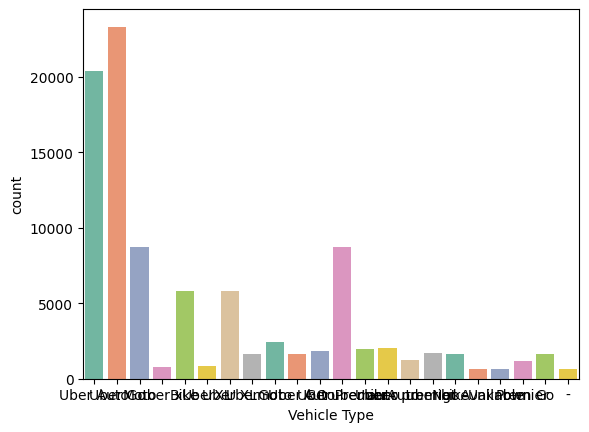

In [ ]:
sns.countplot(data=df, x="Vehicle Type" , palette="Set2")

Text(0.5, 0, 'Booking Status')

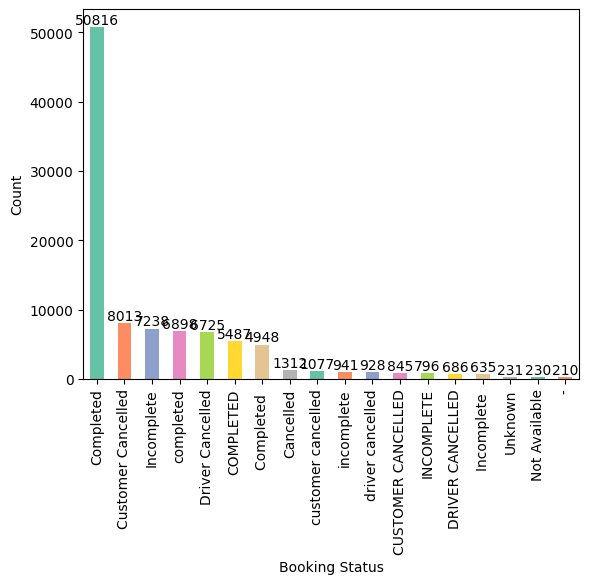

In [ ]:
ax = df['Booking Status'].value_counts().plot(kind='bar', color=sns.color_palette('Set2'))
ax.bar_label(ax.containers[0])
ax.set_ylabel('Count')
ax.set_xlabel('Booking Status')

In [ ]:
print(df.columns.tolist())

['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']


In [ ]:
df["Booking Value"].describe()

,Booking Value
count,83339
unique,10369
top,unknown
freq,1638


In [ ]:
df['Booking Value'] = pd.to_numeric(df['Booking Value'], errors='coerce')
df['Booking Value'].median()

304.3

In [ ]:
df["Booking Value"].mode()

,Booking Value
0,60.0


In [ ]:
df["Booking Value"].std()

2262.8495478554573

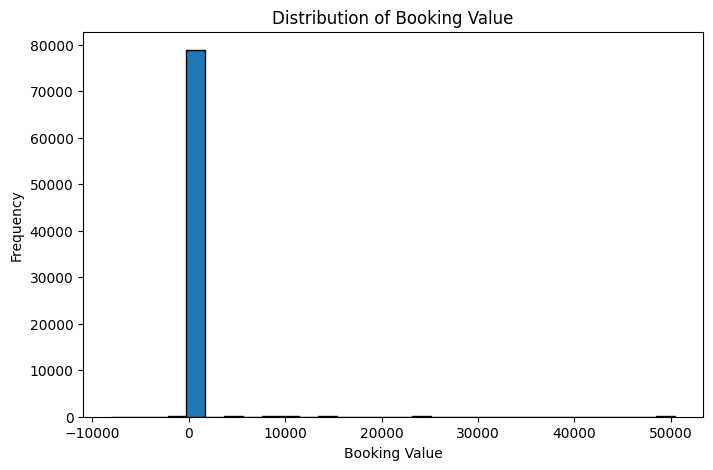

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["Booking Value"].dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Booking Value")
plt.xlabel("Booking Value")
plt.ylabel("Frequency")

plt.show()

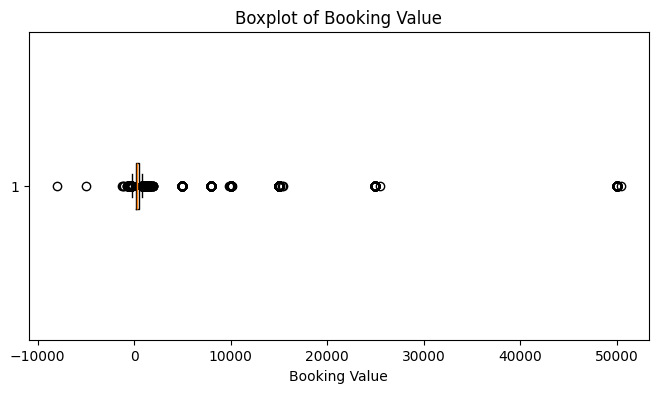

In [ ]:
plt.figure(figsize=(8,4))

plt.boxplot(df["Booking Value"].dropna(), vert=False)

plt.title("Boxplot of Booking Value")
plt.xlabel("Booking Value")

plt.show()

In [ ]:
Q1 = df["Booking Value"].quantile(0.25)
print("Q1 =", Q1)

Q1 = 198.8


In [ ]:
Q3 = df["Booking Value"].quantile(0.75)
print("Q3 =", Q3)

Q3 = 460.4


In [ ]:
IQR = Q3 - Q1
print("IQR =", IQR)

IQR = 261.59999999999997


In [ ]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound =", lower_bound)
print("Upper Bound =", upper_bound)

Lower Bound = -193.59999999999997
Upper Bound = 852.8


In [ ]:
outliers = df[
    (df["Booking Value"] < lower_bound) |
    (df["Booking Value"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 3248


In [ ]:
df.isnull().sum()

,0
Date,4002
Time,3245
Booking ID,296
Booking Status,1310
Customer ID,4900
Vehicle Type,3980
Pickup Location,3335
Drop Location,3391
Avg VTAT,5974
Avg CTAT,9240


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
Date,4.029157
Time,3.267020
Booking ID,0.298009
Booking Status,1.318889
Customer ID,4.933250
Vehicle Type,4.007007
Pickup Location,3.357630
Drop Location,3.414010
Avg VTAT,6.014538
Avg CTAT,9.302700


In [ ]:
df["Booking Status"].value_counts()

,count
Booking Status,
Completed,50816
Customer Cancelled,8013
Incomplete,7238
completed,6898
Driver Cancelled,6725
COMPLETED,5487
Completed,4948
Cancelled,1312
customer cancelled,1077


In [ ]:
df["Booking Status"].value_counts(normalize=True) * 100

,proportion
Booking Status,
Completed,51.844597
Customer Cancelled,8.175196
Incomplete,7.384509
completed,7.037627
Driver Cancelled,6.861125
COMPLETED,5.598066
Completed,5.048155
Cancelled,1.338557
customer cancelled,1.098800


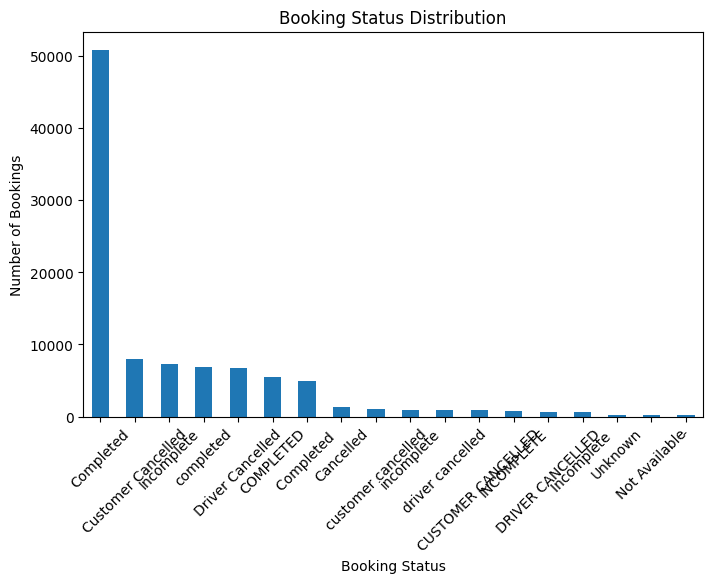

In [ ]:
df["Booking Status"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.show()

In [ ]:
df["Vehicle Type"].value_counts()

,count
Vehicle Type,
Uber Go,23311
Uber Auto,20374
Moto,8748
Uber Premier,8738
Bike,5834
Uber XL,5788
moto,2460
UberAuto,2019
uber auto,1938


In [ ]:
df["Vehicle Type"].value_counts(normalize=True) * 100

,proportion
Vehicle Type,
Uber Go,24.448849
Uber Auto,21.368490
Moto,9.175005
Uber Premier,9.164517
Bike,6.118767
Uber XL,6.070522
moto,2.580077
UberAuto,2.117551
uber auto,2.032597


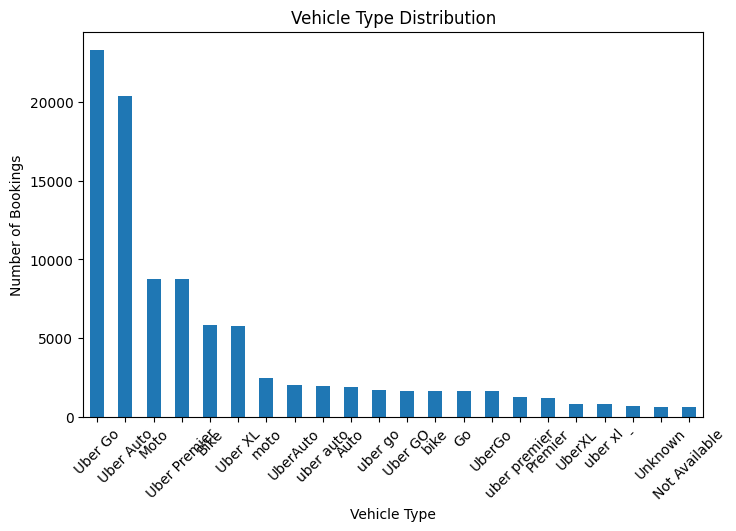

In [ ]:
df["Vehicle Type"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Vehicle Type Distribution")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.show()

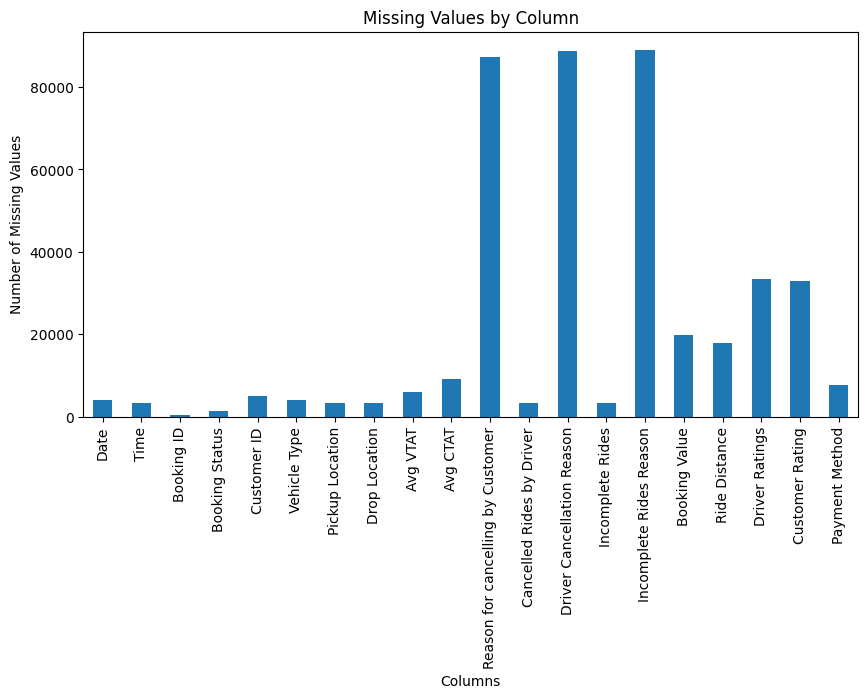

In [ ]:
plt.figure(figsize=(10,5))

df.isnull().sum().plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=90)
plt.show()

In [ ]:
numerical_columns = df.select_dtypes(include=np.number).columns

print(numerical_columns)

Index(['Booking Value'], dtype='object')


In [ ]:
df[numerical_columns].describe()

,Booking Value
count,79628.000000
mean,519.216934
std,2262.849548
min,-8000.000000
25%,198.800000
50%,304.300000
75%,460.400000
max,50412.800000


In [ ]:
df[numerical_columns].mean()

,0
Booking Value,519.216934


In [ ]:
df[numerical_columns].mean()

,0
Booking Value,519.216934


In [ ]:
df[numerical_columns].mode().iloc[0]

,0
Booking Value,60.0


In [ ]:
df[numerical_columns].var()

,0
Booking Value,5.120488e+06


In [ ]:
df[numerical_columns].skew()

,0
Booking Value,17.527792


In [ ]:
skewness = df[numerical_columns].skew()

print(skewness.sort_values(ascending=False))

Booking Value    17.527792
dtype: float64


for all numeric values


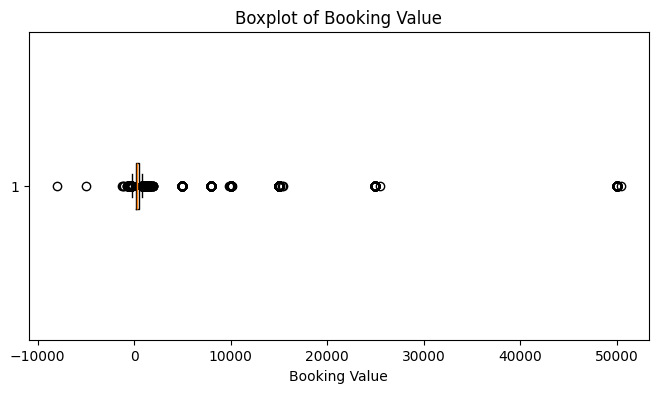

In [ ]:
for col in numerical_columns:

    plt.figure(figsize=(8,4))

    plt.boxplot(df[col].dropna(), vert=False)

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

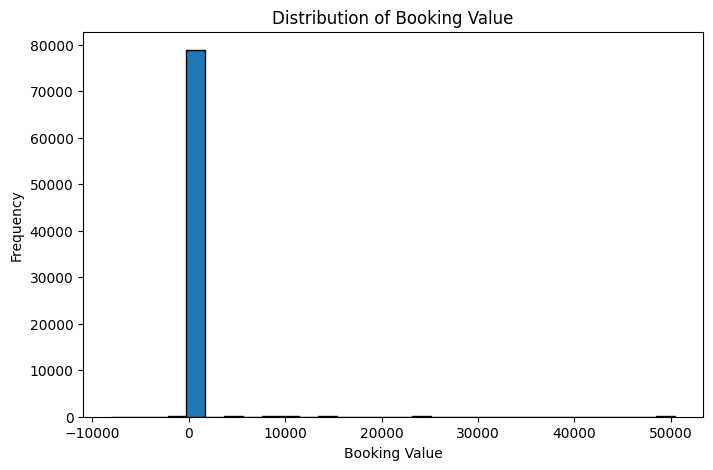

In [ ]:
for col in numerical_columns:

    plt.figure(figsize=(8,5))

    plt.hist(df[col].dropna(), bins=30, edgecolor="black")

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

In [ ]:
from scipy.stats import zscore

In [ ]:
for col in numerical_columns:

    data = df[col].dropna()

    z_scores = zscore(data)

    outliers = data[abs(z_scores) > 3]

    print("--------------------------------")
    print("Column:", col)
    print("Number of Outliers:", len(outliers))

--------------------------------
Column: Booking Value
Number of Outliers: 628


In [ ]:
for col in numerical_columns:

    data = df[col].dropna()

    median = data.median()

    MAD = np.median(np.abs(data - median))

    modified_z = 0.6745 * (data - median) / MAD

    outliers = data[abs(modified_z) > 3.5]

    print("--------------------------------")
    print("Column:", col)
    print("Number of Outliers:", len(outliers))

--------------------------------
Column: Booking Value
Number of Outliers: 2286


In [ ]:
outlier_summary = []

for col in numerical_columns:

    data = df[col].dropna()

    median = data.median()

    MAD = np.median(np.abs(data - median))

    modified_z = 0.6745 * (data - median) / MAD

    outliers = data[abs(modified_z) > 3.5]

    outlier_summary.append({
        "Column": col,
        "Number of Outliers": len(outliers),
        "Percentage of Outliers": (len(outliers) / len(data)) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Column,Number of Outliers,Percentage of Outliers
0,Booking Value,2286,2.870849


In [ ]:
for col in numerical_columns:

    data = df[col].dropna()

    median = data.median()
    MAD = np.median(np.abs(data - median))

    modified_z = 0.6745 * (data - median) / MAD

    outliers = data[abs(modified_z) > 3.5]

    print("\n================================")
    print("Column:", col)
    print("================================")
    print(outliers.head(20))


Column: Booking Value
25      10000.0
95        938.4
174     50000.0
265      1536.3
406     50000.0
419      1442.0
453      8000.0
572       982.6
589      1088.4
623       965.2
672      1448.2
711      1134.1
720      -340.1
735      1035.0
842      8000.0
861      5000.0
965      1016.1
1070      980.3
1119     5000.0
1172     1462.6
Name: Booking Value, dtype: float64


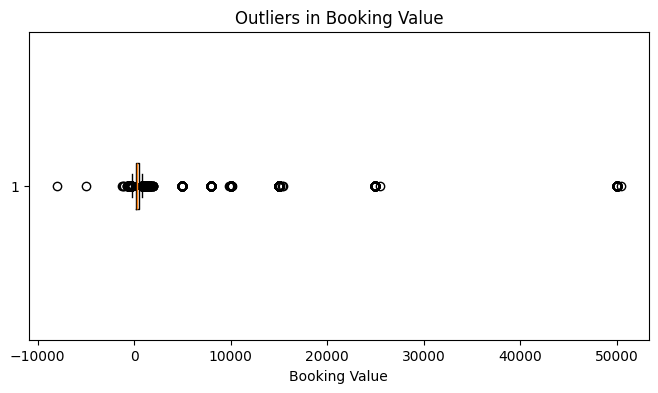

In [ ]:
for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(df[col].dropna(), vert=False)

    plt.title(f"Outliers in {col}")
    plt.xlabel(col)

    plt.show()

In [ ]:
for col in numerical_columns:

    data = df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower) | (data > upper)
    ]

    print("--------------------------------")
    print("Column:", col)
    print("IQR Outliers:", len(outliers))

--------------------------------
Column: Booking Value
IQR Outliers: 3248


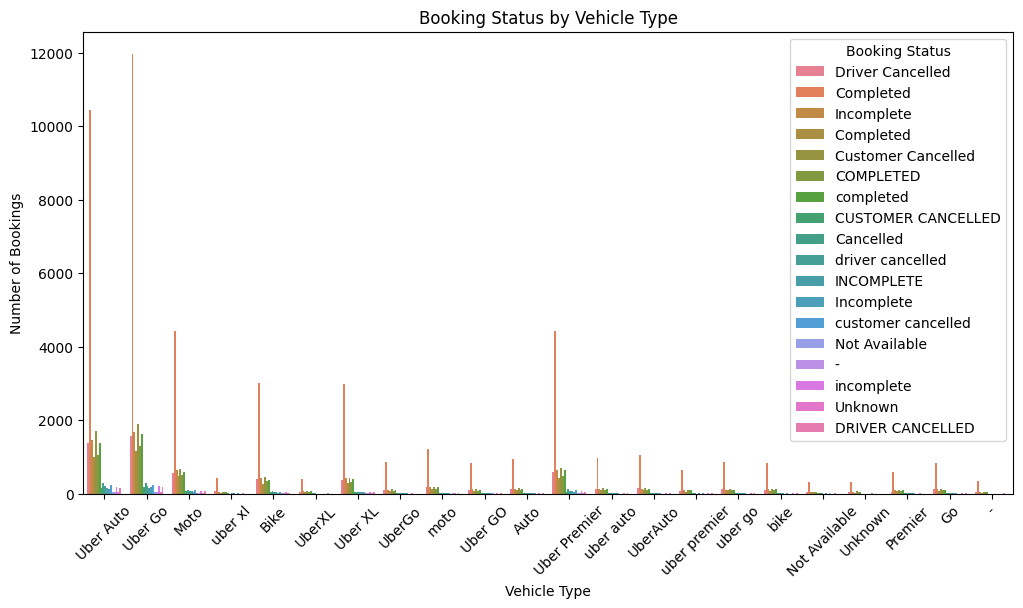

In [ ]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x="Vehicle Type",
    hue="Booking Status"
)

plt.title("Booking Status by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.legend(title="Booking Status")

plt.show()

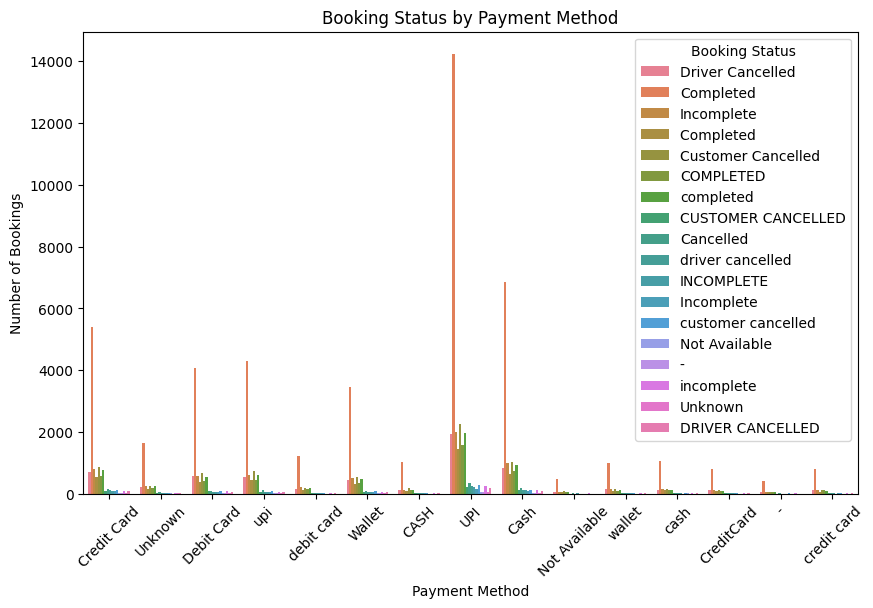

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="Payment Method",
    hue="Booking Status"
)

plt.title("Booking Status by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.legend(title="Booking Status")

plt.show()

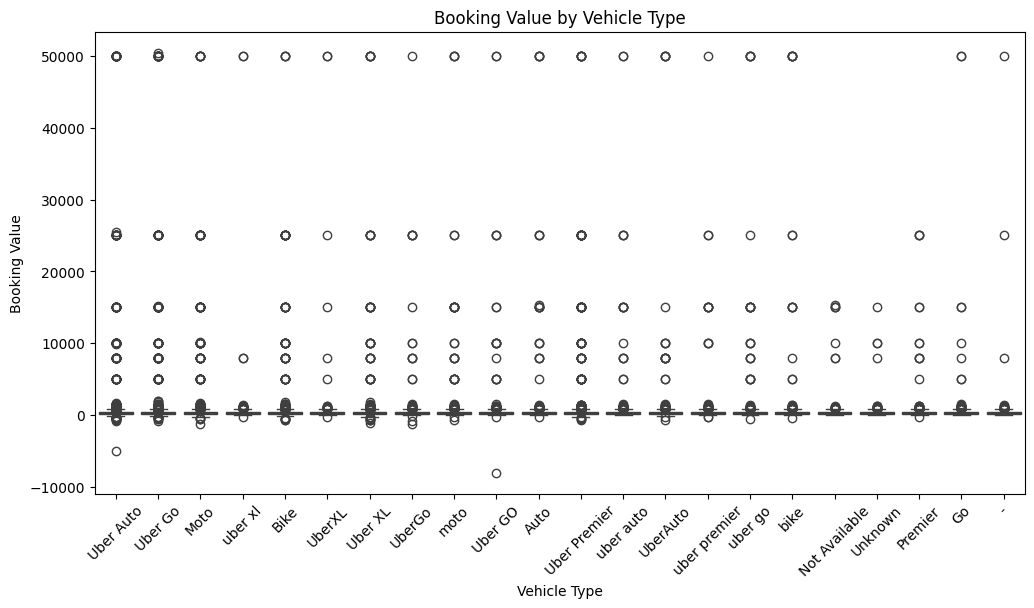

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="Vehicle Type",
    y="Booking Value"
)

plt.title("Booking Value by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Booking Value")

plt.xticks(rotation=45)

plt.show()

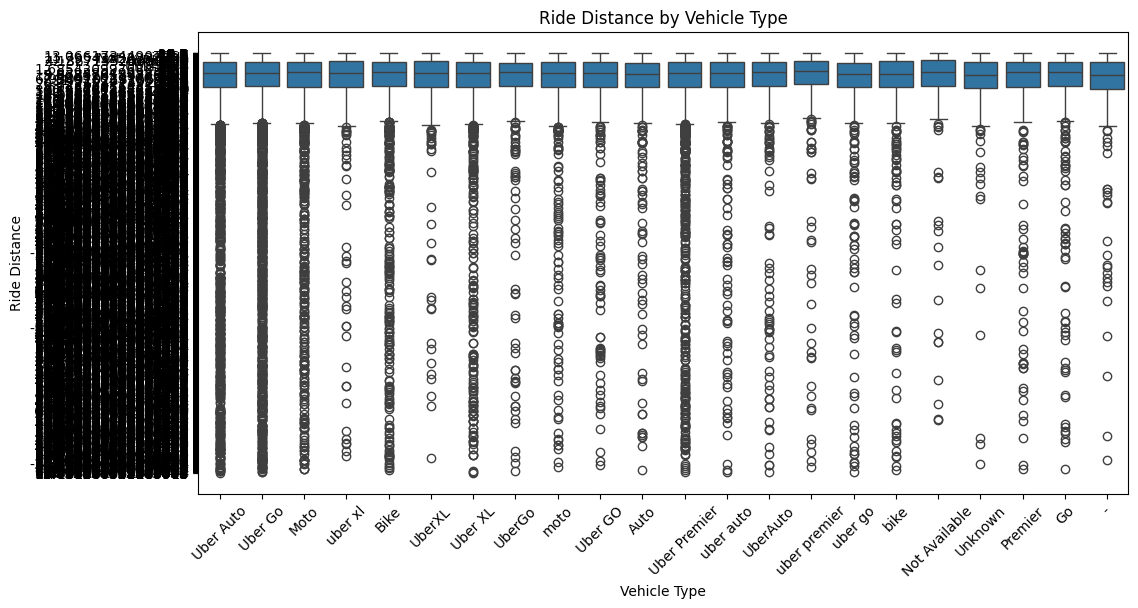

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="Vehicle Type",
    y="Ride Distance"
)

plt.title("Ride Distance by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Ride Distance")

plt.xticks(rotation=45)

plt.show()

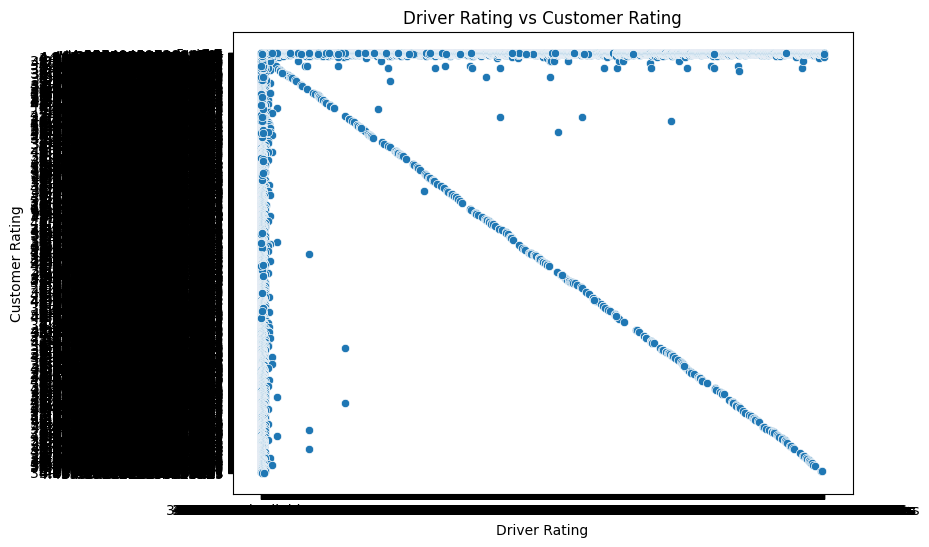

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Driver Ratings",
    y="Customer Rating"
)

plt.title("Driver Rating vs Customer Rating")
plt.xlabel("Driver Rating")
plt.ylabel("Customer Rating")

plt.show()

DTypePromotionError: The DType <class 'numpy.dtypes._PyFloatDType'> could not be promoted by <class 'numpy.dtypes.StrDType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes._PyFloatDType'>)

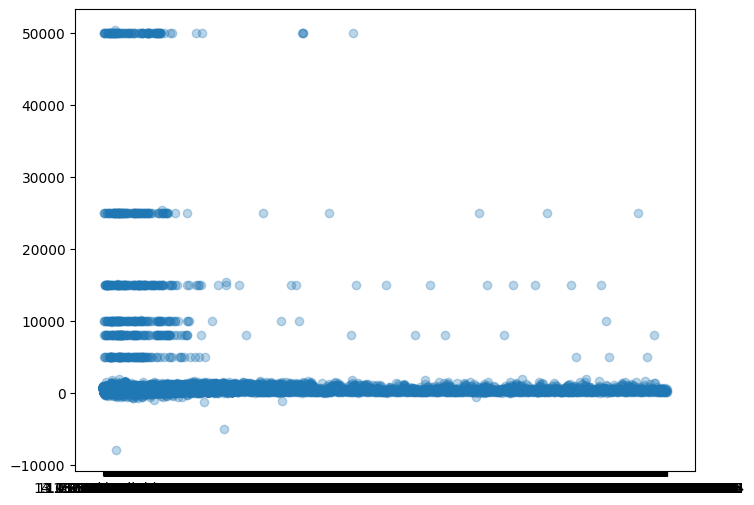

In [ ]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=df,
    x="Ride Distance",
    y="Booking Value",
    scatter_kws={"alpha":0.3}
)

plt.title("Ride Distance vs Booking Value")
plt.xlabel("Ride Distance")
plt.ylabel("Booking Value")

plt.show()

In [ ]:
df["Ride Distance"] = pd.to_numeric(df["Ride Distance"], errors="coerce")
df["Booking Value"] = pd.to_numeric(df["Booking Value"], errors="coerce")

In [ ]:
df[["Ride Distance", "Booking Value"]].corr()

,Ride Distance,Booking Value
Ride Distance,1.000000,0.038677
Booking Value,0.038677,1.000000


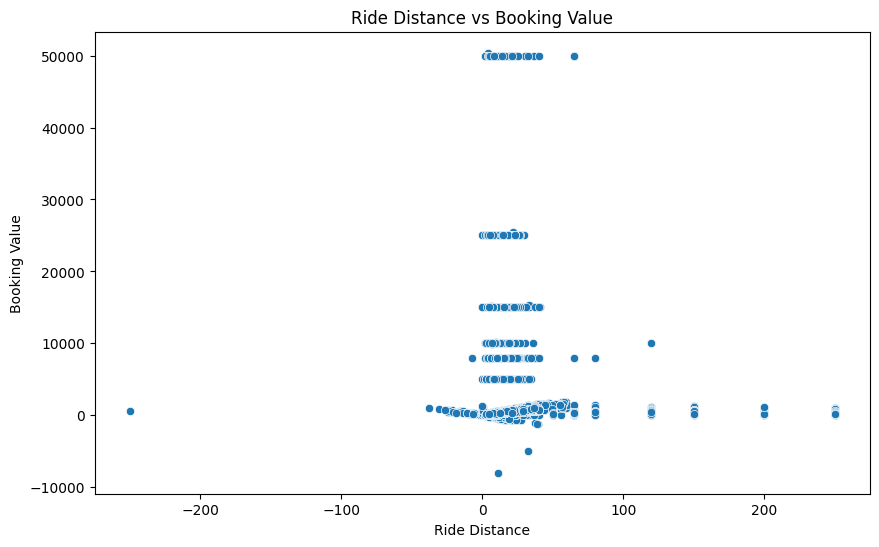

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Ride Distance",
    y="Booking Value"
)

plt.title("Ride Distance vs Booking Value")
plt.xlabel("Ride Distance")
plt.ylabel("Booking Value")

plt.show()

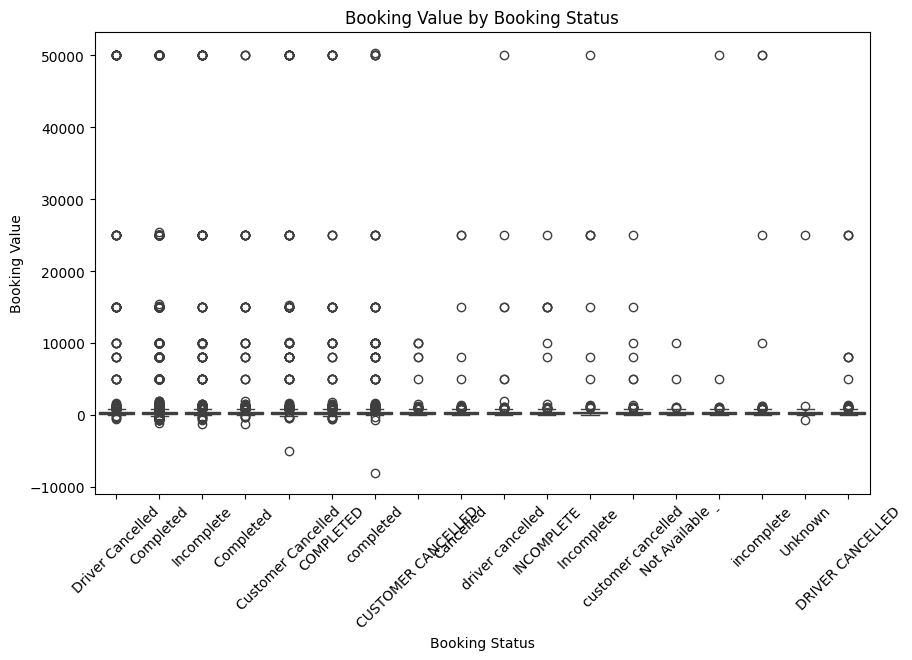

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="Booking Status",
    y="Booking Value"
)

plt.title("Booking Value by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Booking Value")

plt.xticks(rotation=45)
plt.show()

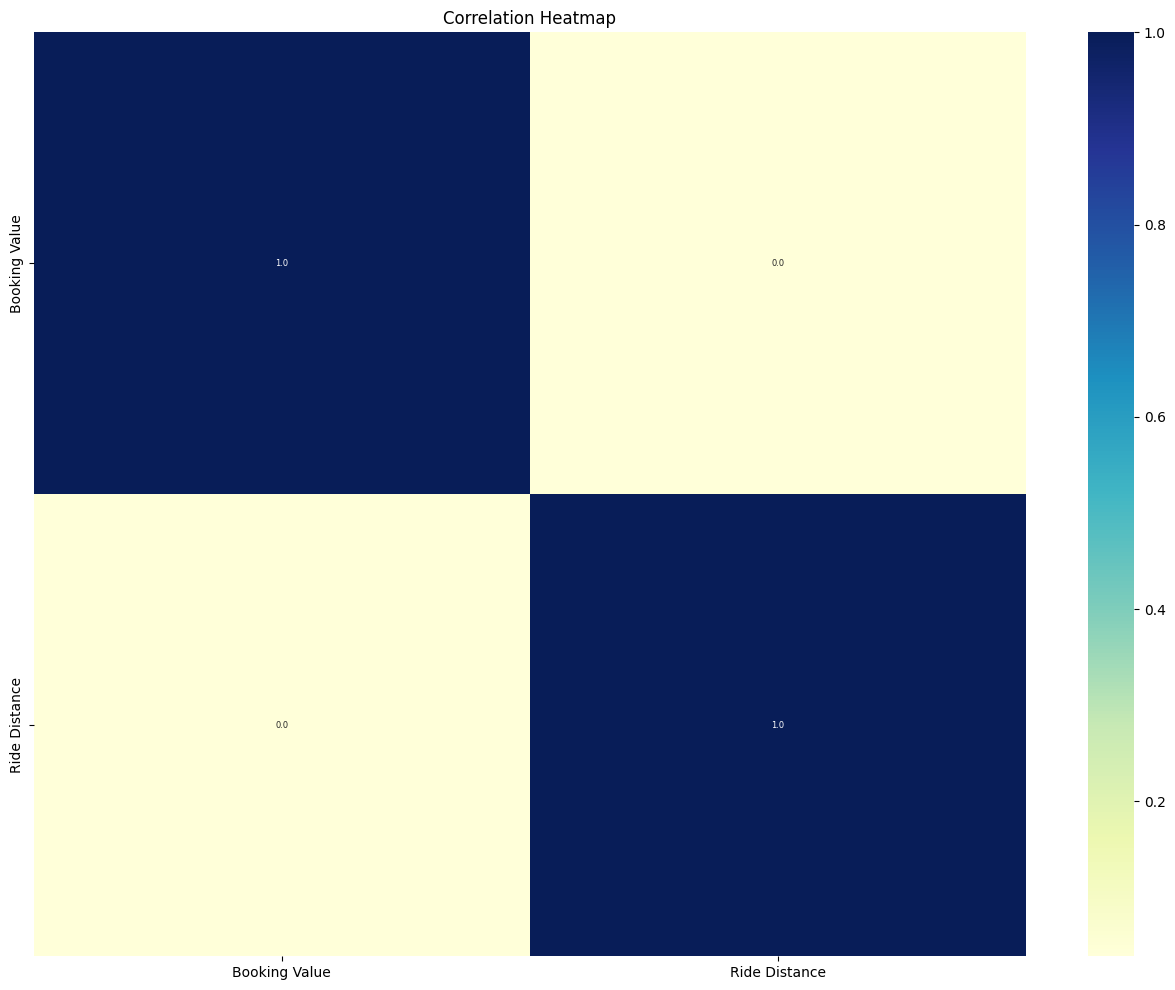

In [ ]:
plt.figure(figsize=(16,12))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    annot_kws={"size":6}
)

plt.title("Correlation Heatmap")
plt.show()

<Axes: xlabel='Ride Distance', ylabel='Booking Value'>

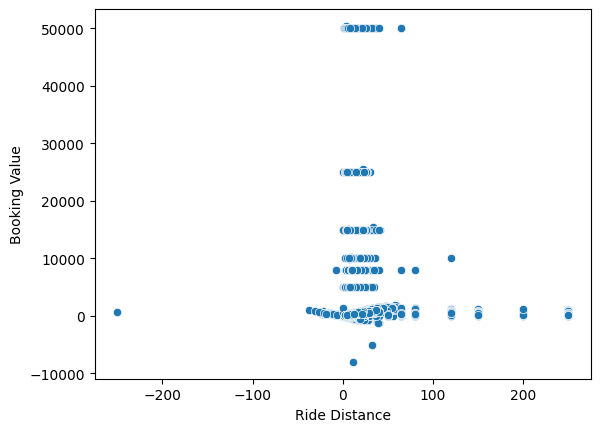

In [ ]:
sns.scatterplot(data = df , x = 'Ride Distance' , y = 'Booking Value' )

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.dtypes

,0
Date,object
Time,object
Booking ID,object
Booking Status,object
Customer ID,object
Vehicle Type,object
Pickup Location,object
Drop Location,object
Avg VTAT,object
Avg CTAT,object


In [ ]:
numerical_columns = df_clean.select_dtypes(include=np.number).columns
df_clean[numerical_columns].dtypes

,0
Booking Value,float64
Ride Distance,float64


In [ ]:
df_clean.isnull().sum().sort_values(ascending=False)

,0
Incomplete Rides Reason,89009
Driver Cancellation Reason,88635
Reason for cancelling by Customer,87186
Driver Ratings,33296
Customer Rating,33007
Ride Distance,21736
Booking Value,19698
Avg CTAT,9240
Payment Method,7606
Avg VTAT,5974


In [ ]:
(df_clean.isnull().sum() / len(df_clean) * 100).sort_values(ascending=False)

,0
Incomplete Rides Reason,89.612992
Driver Cancellation Reason,89.236454
Reason for cancelling by Customer,87.777621
Driver Ratings,33.521938
Customer Rating,33.230977
Ride Distance,21.883495
Booking Value,19.831665
Avg CTAT,9.302700
Payment Method,7.657612
Avg VTAT,6.014538


In [ ]:
(df_clean["Ride Distance"] < 0).sum()

np.int64(65)

In [ ]:
df_clean.loc[
    df_clean["Ride Distance"] < 0,
    "Ride Distance"
] = np.nan

In [ ]:
(df_clean["Ride Distance"] < 0).sum()

np.int64(0)

In [ ]:
df_clean["Driver Ratings"] = pd.to_numeric(df_clean["Driver Ratings"], errors="coerce")
((df_clean["Driver Ratings"] < 1) |
 (df_clean["Driver Ratings"] > 5)).sum()

np.int64(781)

In [ ]:
df_clean.loc[
    (df_clean["Driver Ratings"] < 1) |
    (df_clean["Driver Ratings"] > 5),
    "Driver Ratings"
] = np.nan

In [ ]:
df_clean["Customer Rating"] = pd.to_numeric(df_clean["Customer Rating"], errors="coerce")
((df_clean["Customer Rating"] < 1) |
 (df_clean["Customer Rating"] > 5)).sum()

np.int64(769)

In [ ]:
df_clean.loc[
    (df_clean["Customer Rating"] < 1) |
    (df_clean["Customer Rating"] > 5),
    "Customer Rating"
] = np.nan

In [ ]:
df_clean[numerical_columns].describe()

,Booking Value,Ride Distance
count,79628.000000,77525.000000
mean,519.216934,14.154483
std,2262.849548,16.287765
min,-8000.000000,0.000000
25%,198.800000,6.800000
50%,304.300000,11.100000
75%,460.400000,17.400000
max,50412.800000,250.000000


In [ ]:
df_clean.isnull().sum().sort_values(ascending=False)

,0
Incomplete Rides Reason,89009
Driver Cancellation Reason,88635
Reason for cancelling by Customer,87186
Driver Ratings,44503
Customer Rating,44354
Ride Distance,21801
Booking Value,19698
Avg CTAT,9240
Payment Method,7606
Avg VTAT,5974


In [ ]:
df_clean.dropna()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method


feature engineering

In [ ]:
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce",
    dayfirst=True
)

In [ ]:
df_clean["Date"].dtype

dtype('<M8[ns]')

In [ ]:
df_clean["Month"] = df_clean["Date"].dt.month

In [ ]:
df_clean["Day"] = df_clean["Date"].dt.day_name()

In [ ]:
df_clean["Time"] = pd.to_datetime(
    df_clean["Time"],
    errors="coerce"
)

In [ ]:
df_clean["Hour"] = df_clean["Time"].dt.hour

In [ ]:
def time_period(hour):
    if hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 17:
        return "Afternoon"
    elif hour < 21:
        return "Evening"
    else:
        return "Night"

df_clean["Time Period"] = df_clean["Hour"].apply(time_period)

In [ ]:
df_clean["Year"] = df_clean["Date"].dt.year
df_clean[[
    "Date",
    "Year",
    "Month",
    "Day",
    "Hour",
    "Time Period"
]].head()

,Date,Year,Month,Day,Hour,Time Period
0,2025-09-23,2025.0,9.0,Tuesday,21.0,Night
1,2025-10-13,2025.0,10.0,Monday,16.0,Afternoon
2,NaT,NaN,NaN,NaN,NaN,Night
3,NaT,NaN,NaN,NaN,16.0,Afternoon
4,2025-07-16,2025.0,7.0,Wednesday,23.0,Night


In [ ]:
def distance_category(distance):
    if distance <= 5:
        return "Short"
    elif distance <= 15:
        return "Medium"
    else:
        return "Long"

df_clean["Distance Category"] = df_clean["Ride Distance"].apply(distance_category)

In [ ]:
df_clean["Distance Category"].value_counts()

,count
Distance Category,
Long,47053
Medium,41216
Short,11057


In [ ]:
def booking_category(value):
    if value <= 300:
        return "Low"
    elif value <= 700:
        return "Medium"
    else:
        return "High"

df_clean["Booking Value Category"] = df_clean["Booking Value"].apply(booking_category)

In [ ]:
df_clean["Booking Value Category"].value_counts()

,count
Booking Value Category,
Low,39136
Medium,34089
High,26101


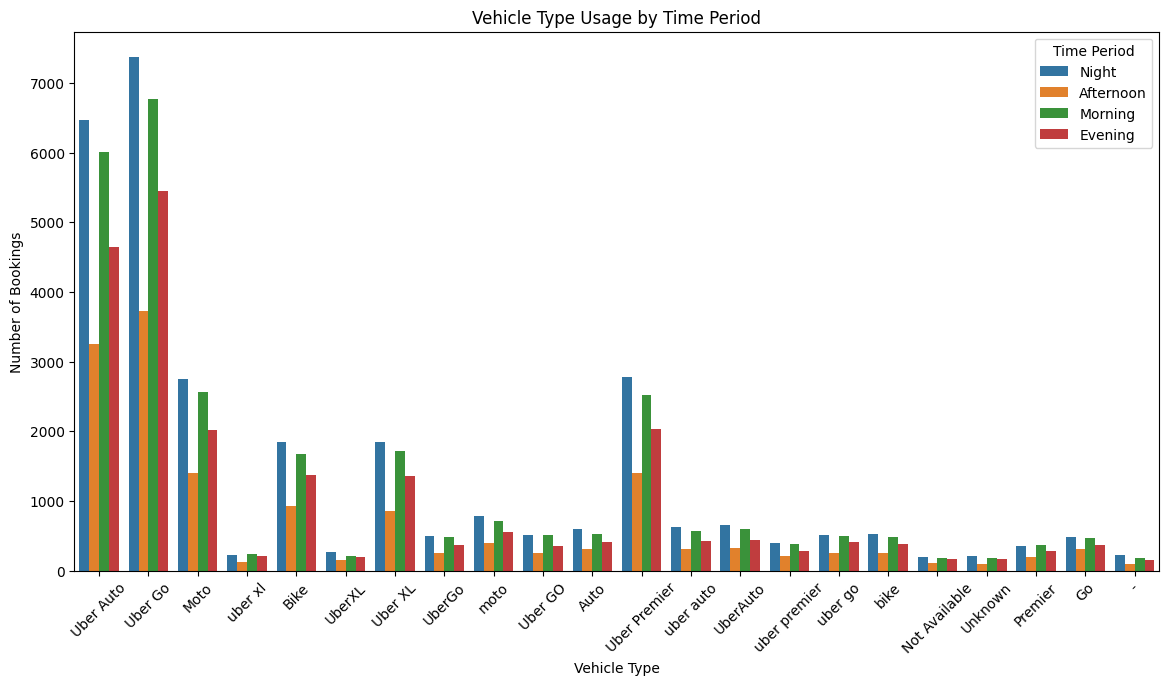

In [ ]:
plt.figure(figsize=(14,7))

sns.countplot(
    data=df_clean,
    x="Vehicle Type",
    hue="Time Period"
)

plt.title("Vehicle Type Usage by Time Period")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.legend(title="Time Period")

plt.show()

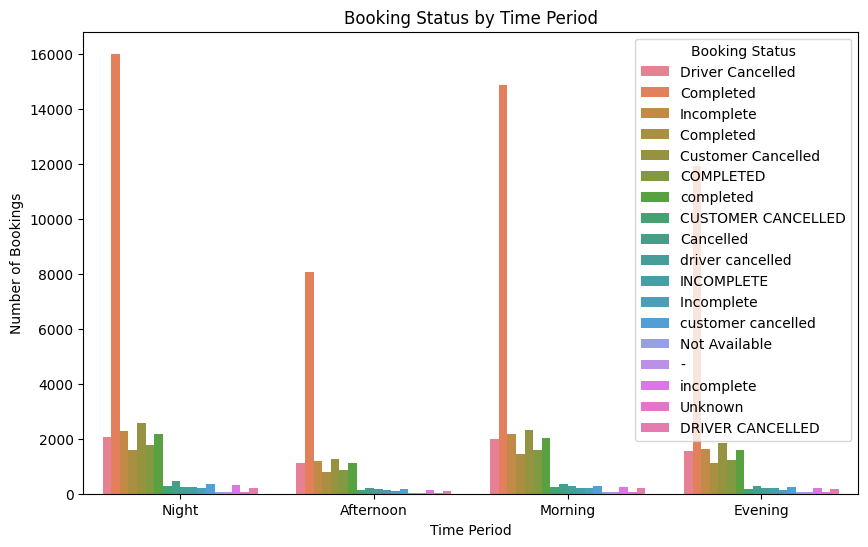

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    x="Time Period",
    hue="Booking Status"
)

plt.title("Booking Status by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Bookings")

plt.show()

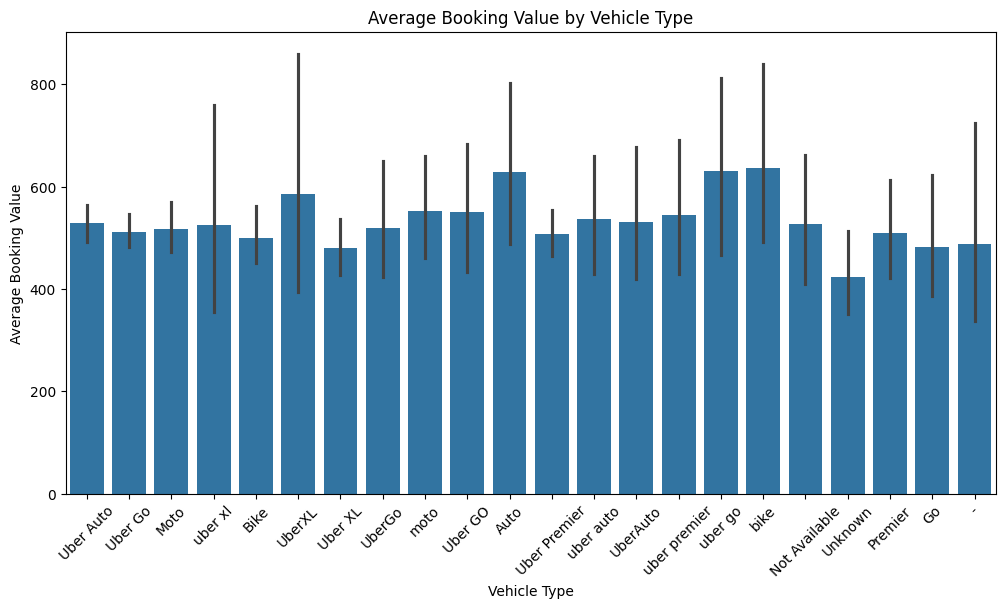

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=df_clean,
    x="Vehicle Type",
    y="Booking Value",
    estimator="mean"
)

plt.title("Average Booking Value by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Booking Value")

plt.xticks(rotation=45)
plt.show()

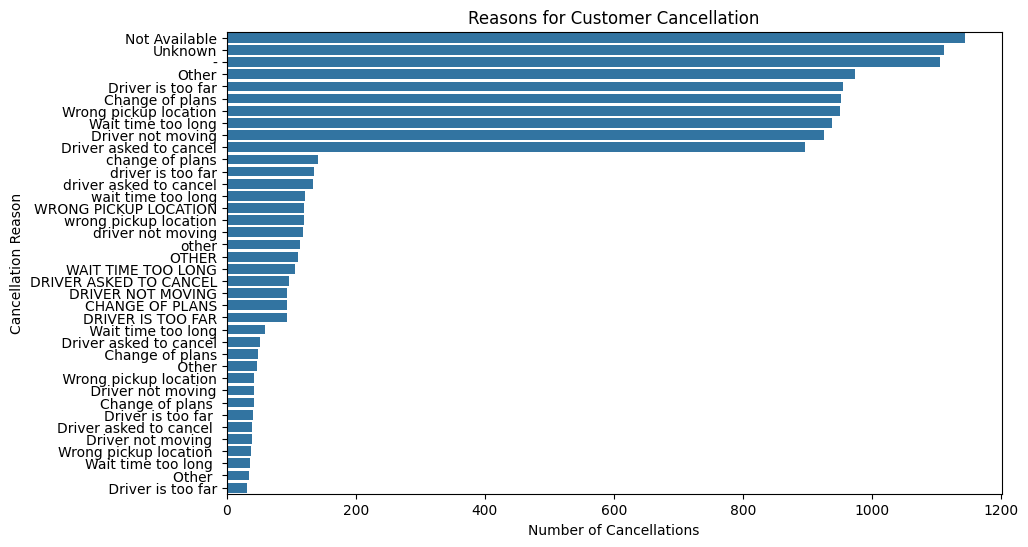

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    y="Reason for cancelling by Customer",
    order=df_clean["Reason for cancelling by Customer"].value_counts().index
)

plt.title("Reasons for Customer Cancellation")
plt.xlabel("Number of Cancellations")
plt.ylabel("Cancellation Reason")

plt.show()

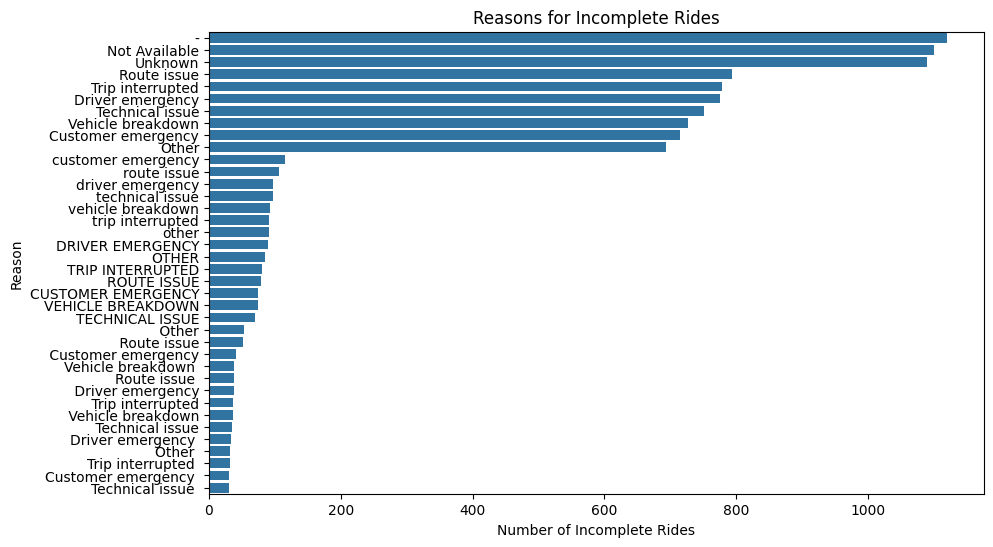

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    y="Incomplete Rides Reason",
    order=df_clean["Incomplete Rides Reason"].value_counts().index
)

plt.title("Reasons for Incomplete Rides")
plt.xlabel("Number of Incomplete Rides")
plt.ylabel("Reason")

plt.show()

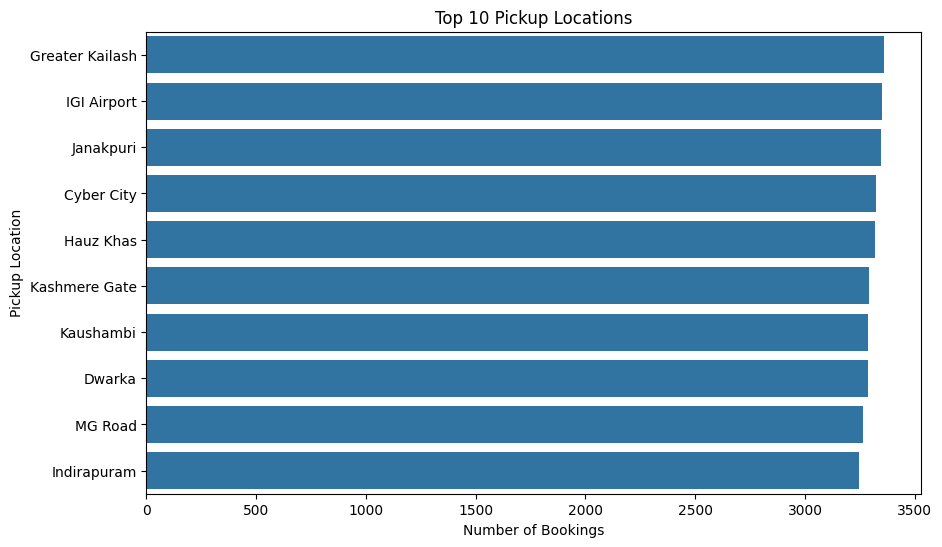

In [ ]:
top_pickup = df_clean["Pickup Location"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_pickup.values,
    y=top_pickup.index
)

plt.title("Top 10 Pickup Locations")
plt.xlabel("Number of Bookings")
plt.ylabel("Pickup Location")

plt.show()

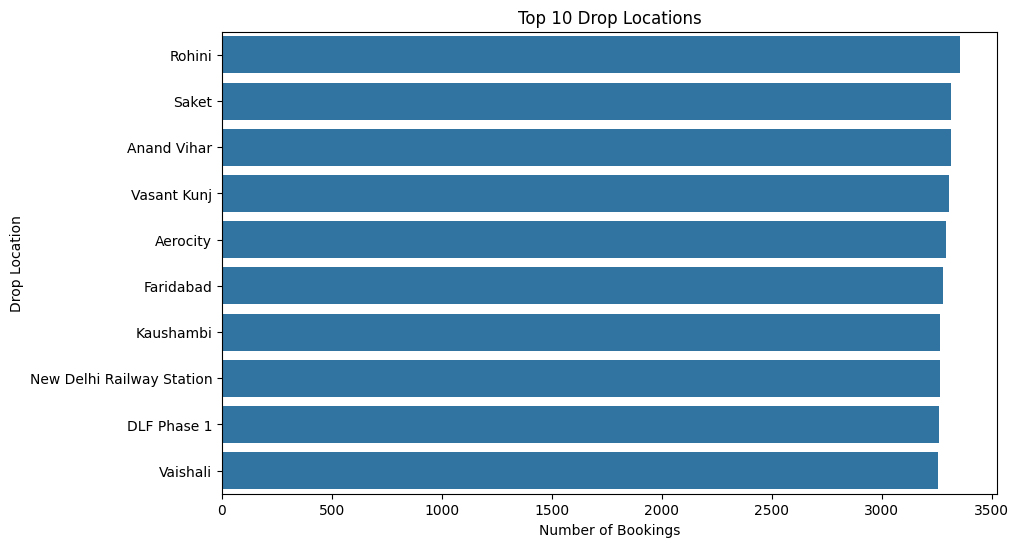

In [ ]:
top_drop = df_clean["Drop Location"].value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_drop.values,
    y=top_drop.index
)

plt.title("Top 10 Drop Locations")
plt.xlabel("Number of Bookings")
plt.ylabel("Drop Location")

plt.show()

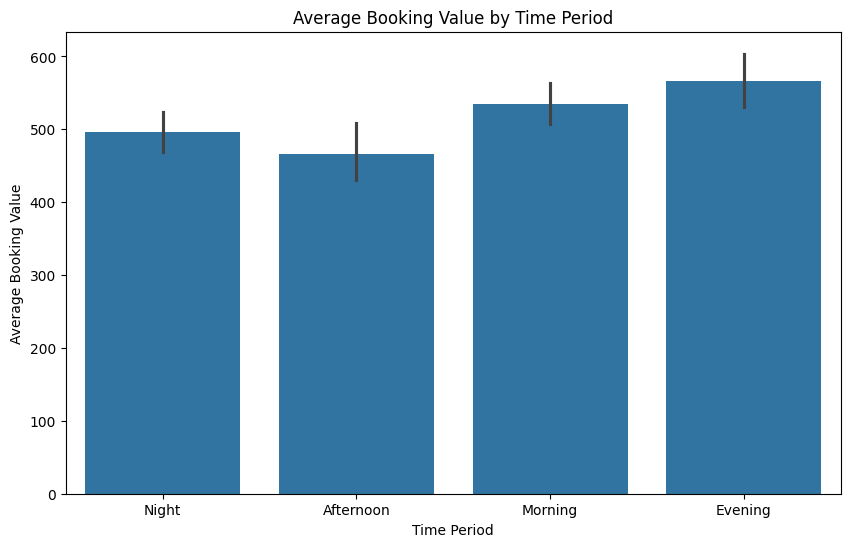

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df_clean,
    x="Time Period",
    y="Booking Value",
    estimator="mean"
)

plt.title("Average Booking Value by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Average Booking Value")

plt.show()

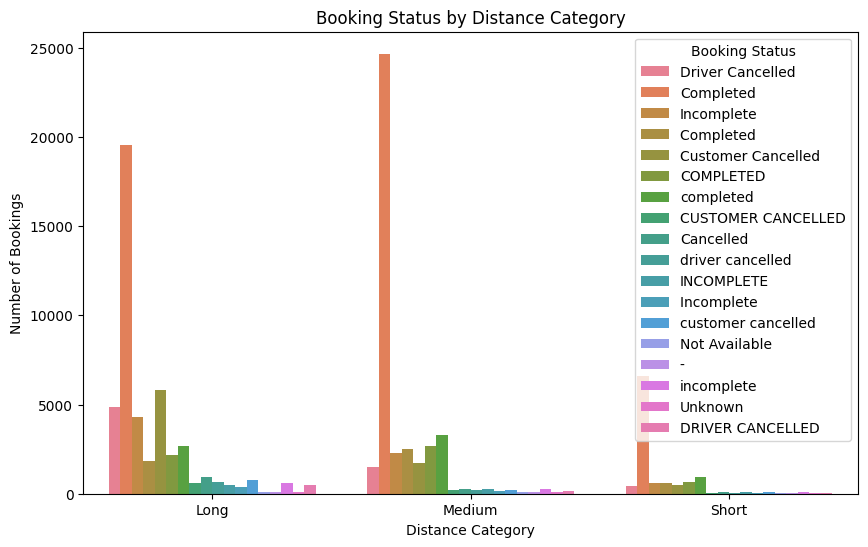

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df_clean,
    x="Distance Category",
    hue="Booking Status"
)

plt.title("Booking Status by Distance Category")
plt.xlabel("Distance Category")
plt.ylabel("Number of Bookings")

plt.show()

In [ ]:
total_bookings = len(df_clean)

print("Total Bookings:", total_bookings)

Total Bookings: 99326


In [ ]:
booking_status_percentage = (
    df_clean["Booking Status"]
    .value_counts(normalize=True) * 100
)

print(booking_status_percentage)

Booking Status
Completed             51.844597
Customer Cancelled     8.175196
Incomplete             7.384509
completed              7.037627
Driver Cancelled       6.861125
COMPLETED              5.598066
Completed              5.048155
Cancelled              1.338557
customer cancelled     1.098800
incomplete             0.960047
driver cancelled       0.946784
CUSTOMER CANCELLED     0.862104
INCOMPLETE             0.812112
DRIVER CANCELLED       0.699886
Incomplete             0.647853
Unknown                0.235676
Not Available          0.234656
-                      0.214251
Name: proportion, dtype: float64


In [ ]:
completion_rate = (
    (df_clean["Booking Status"] == "Completed").sum()
    / len(df_clean)
) * 100

print("Completion Rate:", round(completion_rate, 2), "%")

Completion Rate: 51.16 %


In [ ]:
customer_cancel_rate = (
    (df_clean["Booking Status"] == "Customer Cancelled").sum()
    / len(df_clean)
) * 100

print("Customer Cancellation Rate:", round(customer_cancel_rate, 2), "%")

Customer Cancellation Rate: 8.07 %


In [ ]:
driver_cancel_rate = (
    (df_clean["Booking Status"] == "Driver Cancelled").sum()
    / len(df_clean)
) * 100

print("Driver Cancellation Rate:", round(driver_cancel_rate, 2), "%")

Driver Cancellation Rate: 6.77 %


In [ ]:
incomplete_rate = (
    (df_clean["Booking Status"] == "Incomplete").sum()
    / len(df_clean)
) * 100

print("Incomplete Ride Rate:", round(incomplete_rate, 2), "%")

Incomplete Ride Rate: 7.29 %


In [ ]:
print("Average Booking Value:",
      round(df_clean["Booking Value"].mean(), 2))

print("Average Ride Distance:",
      round(df_clean["Ride Distance"].mean(), 2))

print("Average Driver Rating:",
      round(df_clean["Driver Ratings"].mean(), 2))

print("Average Customer Rating:",
      round(df_clean["Customer Rating"].mean(), 2))

Average Booking Value: 519.22
Average Ride Distance: 14.15
Average Driver Rating: 4.46
Average Customer Rating: 4.56


In [ ]:
popular_vehicle = df_clean["Vehicle Type"].value_counts().idxmax()

print("Most Popular Vehicle:", popular_vehicle)

Most Popular Vehicle: Uber Go


In [ ]:
popular_payment = df_clean["Payment Method"].value_counts().idxmax()

print("Most Popular Payment Method:", popular_payment)

Most Popular Payment Method: UPI


In [ ]:
print(
    df_clean["Reason for cancelling by Customer"]
    .value_counts()
    .head(5)
)

Reason for cancelling by Customer
Not Available        1144
Unknown              1112
-                    1105
Other                 974
Driver is too far     955
Name: count, dtype: int64


In [ ]:
print(
    df_clean["Incomplete Rides Reason"]
    .value_counts()
    .head(5)
)

Incomplete Rides Reason
-                   1120
Not Available       1101
Unknown             1089
Route issue          793
Trip interrupted     779
Name: count, dtype: int64


In [ ]:
print(
    df_clean["Pickup Location"]
    .value_counts()
    .head(5)
)

Pickup Location
Greater Kailash    3362
IGI Airport        3350
Janakpuri          3344
Cyber City         3324
Hauz Khas          3318
Name: count, dtype: int64


In [ ]:
print(
    df_clean["Drop Location"]
    .value_counts()
    .head(5)
)

Drop Location
Rohini         3356
Saket          3317
Anand Vihar    3316
Vasant Kunj    3305
Aerocity       3291
Name: count, dtype: int64


In [ ]:
df_clean["Avg VTAT"] = pd.to_numeric(df_clean["Avg VTAT"], errors="coerce")
df_clean["Avg CTAT"] = pd.to_numeric(df_clean["Avg CTAT"], errors="coerce")
df_clean[
    [
        "Avg VTAT",
        "Avg CTAT",
        "Booking Value",
        "Ride Distance",
        "Driver Ratings",
        "Customer Rating"
    ]
].corr()

,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating
Avg VTAT,1.000000,0.088626,0.000829,-0.000921,-0.000707,0.000504
Avg CTAT,0.088626,1.000000,0.010026,0.035414,-0.000207,0.001353
Booking Value,0.000829,0.010026,1.000000,0.038816,-0.000262,-0.002597
Ride Distance,-0.000921,0.035414,0.038816,1.000000,0.002037,0.001661
Driver Ratings,-0.000707,-0.000207,-0.000262,0.002037,1.000000,0.003549
Customer Rating,0.000504,0.001353,-0.002597,0.001661,0.003549,1.000000


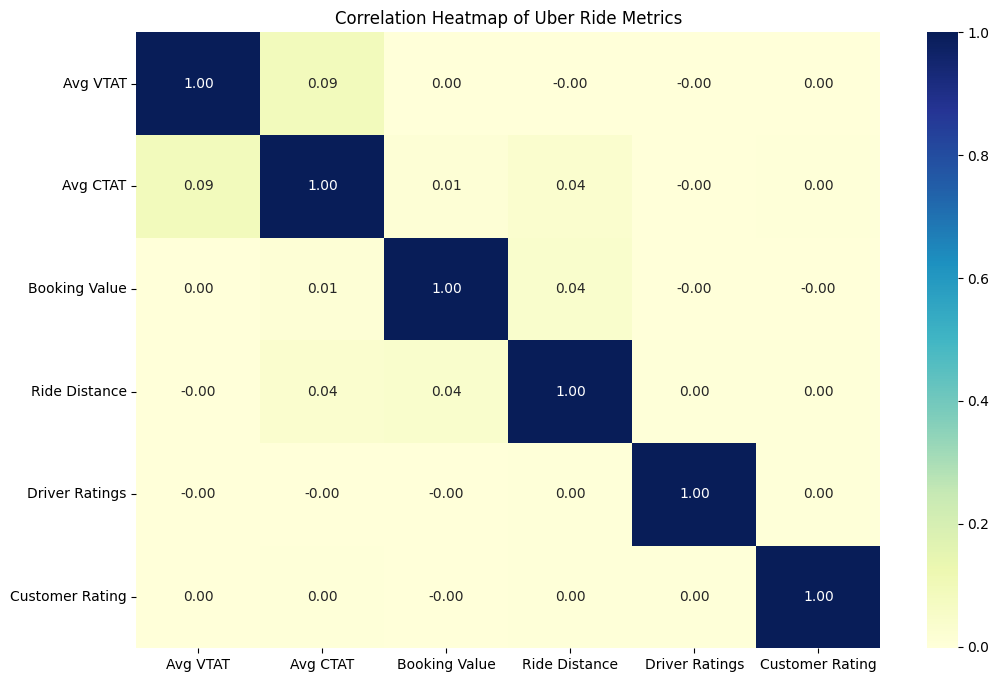

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df_clean[
        [
            "Avg VTAT",
            "Avg CTAT",
            "Booking Value",
            "Ride Distance",
            "Driver Ratings",
            "Customer Rating"
        ]
    ].corr(),
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Correlation Heatmap of Uber Ride Metrics")
plt.show()

In [ ]:
customer_reasons = df_clean[
    (df_clean["Booking Status"] == "Customer Cancelled")
]["Reason for cancelling by Customer"]

customer_reasons = customer_reasons[
    ~customer_reasons.isin(["Unknown", "-"])
]

print(customer_reasons.value_counts())

Reason for cancelling by Customer
Driver is too far          716
Wait time too long         714
Other                      710
Change of plans            704
Wrong pickup location      681
Driver not moving          679
Driver asked to cancel     663
driver asked to cancel     105
change of plans            101
driver is too far           99
wait time too long          97
Not Available               96
WRONG PICKUP LOCATION       91
other                       90
OTHER                       87
driver not moving           84
WAIT TIME TOO LONG          83
wrong pickup location       82
DRIVER ASKED TO CANCEL      73
DRIVER IS TOO FAR           71
CHANGE OF PLANS             71
DRIVER NOT MOVING           66
 Wait time too long         41
 Driver asked to cancel     35
 Change of plans            33
Change of plans             33
 Other                      32
Wrong pickup location       29
 Driver not moving          28
Wait time too long          28
Driver not moving           28
Drive

In [ ]:
customer_reason_percentage = (
    customer_reasons.value_counts(normalize=True) * 100
)

print(customer_reason_percentage.round(2))

Reason for cancelling by Customer
Driver is too far          10.91
Wait time too long         10.88
Other                      10.81
Change of plans            10.72
Wrong pickup location      10.37
Driver not moving          10.34
Driver asked to cancel     10.10
driver asked to cancel      1.60
change of plans             1.54
driver is too far           1.51
wait time too long          1.48
Not Available               1.46
WRONG PICKUP LOCATION       1.39
other                       1.37
OTHER                       1.33
driver not moving           1.28
WAIT TIME TOO LONG          1.26
wrong pickup location       1.25
DRIVER ASKED TO CANCEL      1.11
DRIVER IS TOO FAR           1.08
CHANGE OF PLANS             1.08
DRIVER NOT MOVING           1.01
 Wait time too long         0.62
 Driver asked to cancel     0.53
 Change of plans            0.50
Change of plans             0.50
 Other                      0.49
Wrong pickup location       0.44
 Driver not moving          0.43
Wait time

In [ ]:
total_customer_cancelled = (
    df_clean["Booking Status"] == "Customer Cancelled"
).sum()

print("Total Customer Cancellations:", total_customer_cancelled)

Total Customer Cancellations: 8013


In [ ]:
unknown_count = customer_reasons.isin(["Unknown", "-"]).sum()

print("Unknown/Unspecified:", unknown_count)

Unknown/Unspecified: 0


In [ ]:
all_customer_reasons = df_clean[
    df_clean["Booking Status"] == "Customer Cancelled"
]["Reason for cancelling by Customer"]

unspecified = all_customer_reasons.isin(["Unknown", "-"]).sum()

print("Unspecified cancellations:", unspecified)
print(
    "Percentage:",
    round(unspecified / len(all_customer_reasons) * 100, 2),
    "%"
)

Unspecified cancellations: 174
Percentage: 2.17 %


In [ ]:
driver_reasons = df_clean[
    df_clean["Booking Status"] == "Driver Cancelled"
]["Driver Cancellation Reason"]

print(driver_reasons.value_counts().head(10))

Driver Cancellation Reason
Customer not reachable      528
Wrong pickup location       526
Vehicle issue               524
Other                       522
Personal emergency          515
Too far                     513
Customer asked to cancel    489
Traffic                     453
vehicle issue                79
Not Available                78
Name: count, dtype: int64


In [ ]:
incomplete_reasons = df_clean[
    df_clean["Booking Status"] == "Incomplete"
]["Incomplete Rides Reason"]

print(incomplete_reasons.value_counts().head(10))

Incomplete Rides Reason
Route issue           583
Trip interrupted      579
Driver emergency      578
Technical issue       570
Vehicle breakdown     527
Customer emergency    520
Other                 517
customer emergency     87
driver emergency       78
route issue            76
Name: count, dtype: int64


In [ ]:
revenue_vehicle = df_clean.groupby(
    "Vehicle Type"
)["Booking Value"].sum().sort_values(ascending=False)

print(revenue_vehicle)

Vehicle Type
Uber Go          9568091.8
Uber Auto        8594494.1
Moto             3625573.8
Uber Premier     3578732.6
Bike             2336768.8
Uber XL          2257866.3
moto             1078353.7
Auto              934786.6
UberAuto          859850.1
bike              851653.6
uber go           833102.6
uber auto         824959.0
Uber GO           730072.7
UberGo            674755.5
Go                621436.5
uber premier      545362.9
Premier           500425.5
UberXL            385188.2
uber xl           338111.6
-                 272978.1
Not Available     261167.8
Unknown           215007.3
Name: Booking Value, dtype: float64


In [ ]:
revenue_time = df_clean.groupby(
    "Time Period"
)["Booking Value"].sum().sort_values(ascending=False)

print(revenue_time)

Time Period
Night        12451718.0
Morning      12419384.0
Evening      10535503.8
Afternoon     5937600.2
Name: Booking Value, dtype: float64


In [ ]:
hourly_bookings = df_clean["Hour"].value_counts().sort_index()

print(hourly_bookings)

Hour
0.0     3581
1.0     3667
2.0     1859
3.0     1886
4.0     1933
5.0     1871
6.0     1894
7.0     5931
8.0     6021
9.0     6049
10.0    5953
11.0    3173
12.0    3101
13.0    3202
14.0    3292
15.0    3138
16.0    3136
17.0    5828
18.0    5625
19.0    5836
20.0    5721
21.0    5573
22.0    3532
23.0    3603
Name: count, dtype: int64


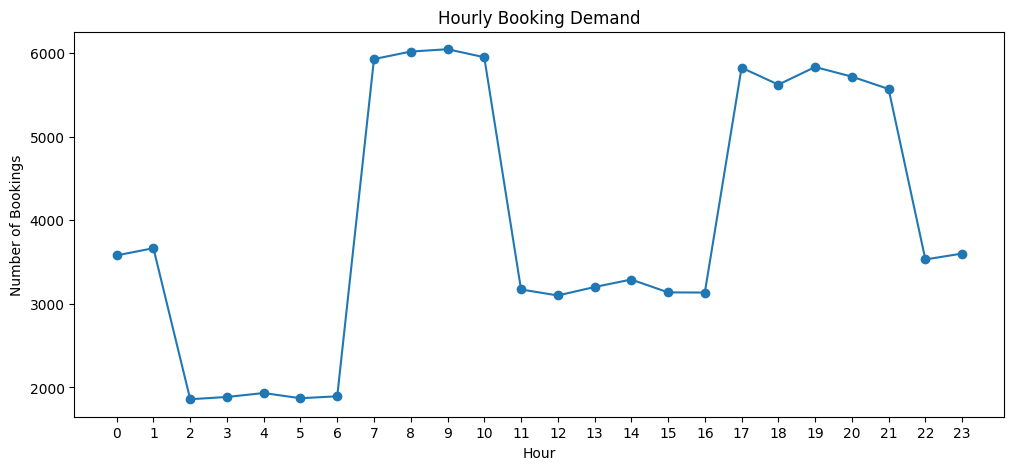

In [ ]:
hourly_bookings.plot(
    kind="line",
    figsize=(12,5),
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Number of Bookings")
plt.title("Hourly Booking Demand")
plt.xticks(range(24))
plt.show()

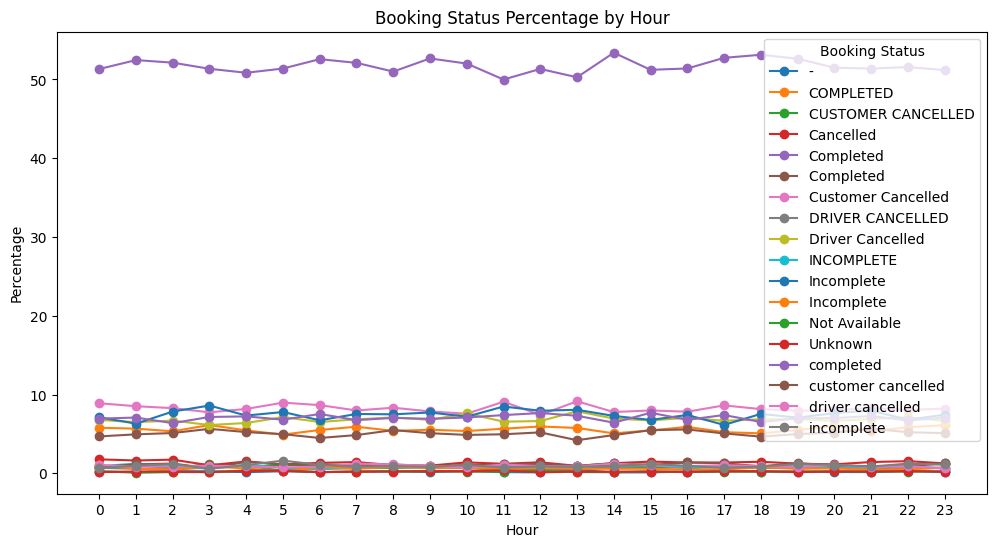

In [ ]:
hour_status = pd.crosstab(
    df_clean["Hour"],
    df_clean["Booking Status"],
    normalize="index"
) * 100

hour_status.plot(
    kind="line",
    figsize=(12,6),
    marker="o"
)

plt.title("Booking Status Percentage by Hour")
plt.xlabel("Hour")
plt.ylabel("Percentage")
plt.xticks(range(24))
plt.show()

In [ ]:
revenue = df_clean.groupby("Vehicle Type")["Booking Value"].sum()

revenue_percentage = (revenue / revenue.sum()) * 100

print(revenue_percentage.sort_values(ascending=False).round(2))

Vehicle Type
Uber Go          23.99
Uber Auto        21.55
Moto              9.09
Uber Premier      8.97
Bike              5.86
Uber XL           5.66
moto              2.70
Auto              2.34
UberAuto          2.16
bike              2.14
uber go           2.09
uber auto         2.07
Uber GO           1.83
UberGo            1.69
Go                1.56
uber premier      1.37
Premier           1.25
UberXL            0.97
uber xl           0.85
-                 0.68
Not Available     0.65
Unknown           0.54
Name: Booking Value, dtype: float64


In [ ]:
df_clean["Revenue per KM"] = (
    df_clean["Booking Value"] / df_clean["Ride Distance"]
)

print(
    df_clean.groupby("Vehicle Type")["Revenue per KM"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

Vehicle Type
-                  inf
Auto               inf
Bike               inf
Moto               inf
Not Available      inf
Premier            inf
UberXL             inf
Uber Auto          inf
Uber GO            inf
Uber Go            inf
Uber Premier       inf
Uber XL            inf
UberAuto           inf
UberGo             inf
uber xl            inf
Unknown            inf
moto               inf
uber auto          inf
uber go            inf
uber premier     62.83
bike             58.06
Go               55.38
Name: Revenue per KM, dtype: float64


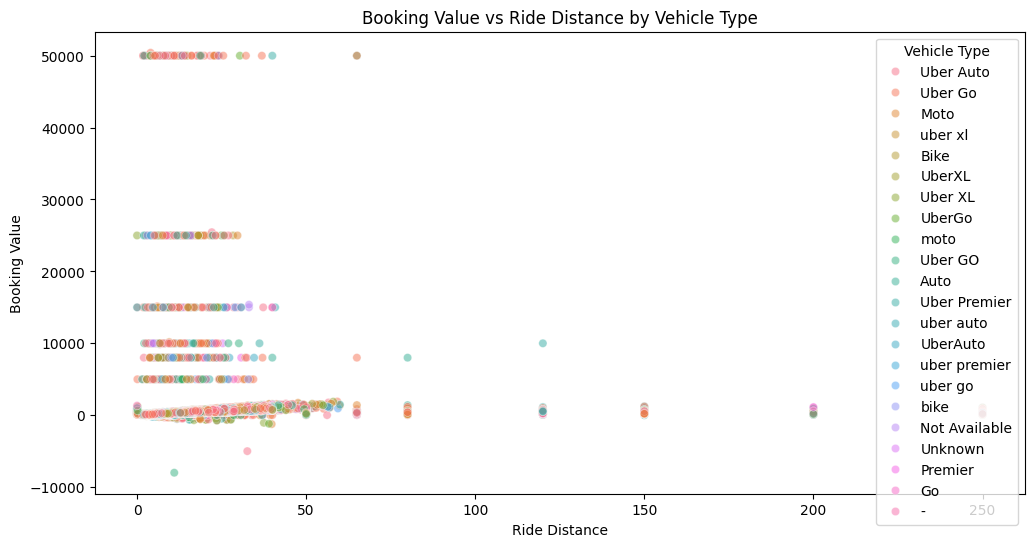

In [ ]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    data=df_clean,
    x="Ride Distance",
    y="Booking Value",
    hue="Vehicle Type",
    alpha=0.5
)

plt.title("Booking Value vs Ride Distance by Vehicle Type")
plt.show()

In [ ]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_demand = df_clean["Day"].value_counts().reindex(day_order)

print(day_demand)

Day
Monday        9952
Tuesday      10055
Wednesday    10223
Thursday     10060
Friday       10014
Saturday     10166
Sunday       10114
Name: count, dtype: int64


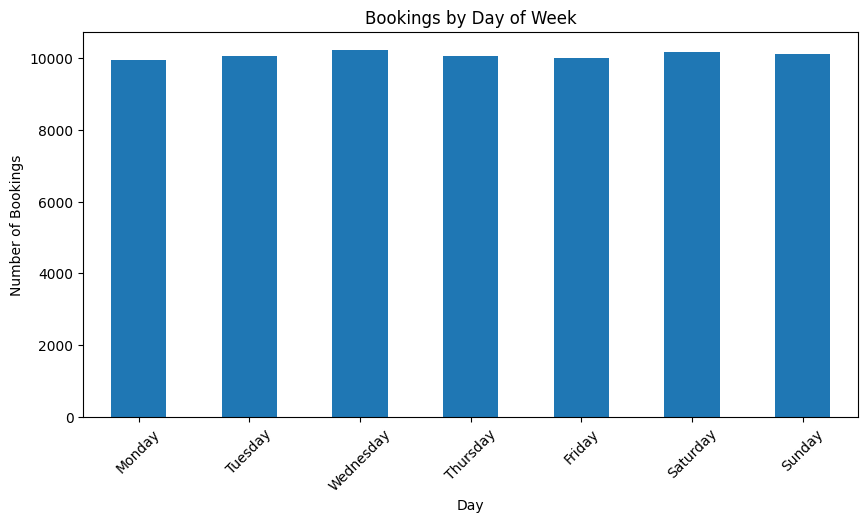

In [ ]:
day_demand.plot(kind="bar", figsize=(10,5))

plt.title("Bookings by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

In [ ]:
df_clean["Day Type"] = df_clean["Day"].apply(
    lambda x: "Weekend" if x in ["Saturday", "Sunday"] else "Weekday"
)

In [ ]:
print(df_clean["Day Type"].value_counts())

Day Type
Weekday    79046
Weekend    20280
Name: count, dtype: int64


In [ ]:
print(
    df_clean.groupby("Day Type")["Booking Value"]
    .mean()
    .round(2)
)

Day Type
Weekday    518.65
Weekend    521.44
Name: Booking Value, dtype: float64


In [ ]:
location_status = pd.crosstab(
    df_clean["Pickup Location"],
    df_clean["Booking Status"],
    normalize="index"
) * 100

location_status["Customer Cancellation"] = (
    location_status.get("Customer Cancelled", 0)
)

print(
    location_status["Customer Cancellation"]
    .sort_values(ascending=False)
    .head(10)
)

Pickup Location
gurgaon          11.320755
delhi            10.937500
 delhi           10.227273
Lajpat nagar     10.160428
Unknown           9.823183
GHAZIABAD         9.734513
IGI Airport       9.451681
Not Available     9.174312
Kashmere Gate     9.161012
DLF Phase 1       9.025609
Name: Customer Cancellation, dtype: float64


In [ ]:
rating_status = df_clean.groupby("Booking Status")[
    ["Driver Ratings", "Customer Rating"]
].mean()

print(rating_status.round(2))

                    Driver Ratings  Customer Rating
Booking Status                                     
-                             4.46             4.58
COMPLETED                     4.45             4.56
CUSTOMER CANCELLED             NaN              NaN
Cancelled                      NaN              NaN
Completed                     4.46             4.56
Completed                     4.45             4.56
Customer Cancelled             NaN              NaN
DRIVER CANCELLED               NaN              NaN
Driver Cancelled               NaN              NaN
INCOMPLETE                    4.47             4.56
Incomplete                    4.48             4.55
Incomplete                    4.43             4.52
Not Available                 4.46             4.51
Unknown                       4.47             4.53
completed                     4.47             4.54
customer cancelled             NaN              NaN
driver cancelled               NaN              NaN
incomplete  

In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    df_clean["Vehicle Type"],
    df_clean["Booking Status"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 412.4865673623173
p-value: 0.022620535564393203


statisticaly significant result <.05


In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    df_clean["Time Period"],
    df_clean["Booking Status"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 43.909244864163846
p-value: 0.748789269489592


In [ ]:
business_summary = pd.DataFrame({
    "Metric": [
        "Total Bookings",
        "Completion Rate (%)",
        "Customer Cancellation Rate (%)",
        "Driver Cancellation Rate (%)",
        "Incomplete Ride Rate (%)",
        "Average Booking Value",
        "Average Ride Distance",
        "Average Driver Rating",
        "Average Customer Rating"
    ],
    "Value": [
        len(df_clean),
        round(completion_rate, 2),
        round(customer_cancel_rate, 2),
        round(driver_cancel_rate, 2),
        round(incomplete_rate, 2),
        round(df_clean["Booking Value"].mean(), 2),
        round(df_clean["Ride Distance"].mean(), 2),
        round(df_clean["Driver Ratings"].mean(), 2),
        round(df_clean["Customer Rating"].mean(), 2)
    ]
})

print(business_summary)

                           Metric     Value
0                  Total Bookings  99326.00
1             Completion Rate (%)     51.16
2  Customer Cancellation Rate (%)      8.07
3    Driver Cancellation Rate (%)      6.77
4        Incomplete Ride Rate (%)      7.29
5           Average Booking Value    519.22
6           Average Ride Distance     14.15
7           Average Driver Rating      4.46
8         Average Customer Rating      4.56


In [ ]:
print("Most Popular Vehicle:")
print(df_clean["Vehicle Type"].value_counts().idxmax())

print("\nMost Popular Payment Method:")
print(df_clean["Payment Method"].value_counts().idxmax())

print("\nMost Popular Pickup Location:")
print(df_clean["Pickup Location"].value_counts().idxmax())

print("\nMost Popular Drop Location:")
print(df_clean["Drop Location"].value_counts().idxmax())

print("\nPeak Booking Hour:")
print(df_clean["Hour"].value_counts().idxmax())

Most Popular Vehicle:
Uber Go

Most Popular Payment Method:
UPI

Most Popular Pickup Location:
Greater Kailash

Most Popular Drop Location:
Rohini

Peak Booking Hour:
9.0
